In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt

In [2]:
df = pd.read_csv(
    r"C:\Users\hp\Downloads\Telegram Desktop\SalesProject.csv",
    encoding="latin-1"
)

print(df.head())

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156  11-08-2016  11-11-2016    Second Class    CG-12520   
1       2  CA-2016-152156  11-08-2016  11-11-2016    Second Class    CG-12520   
2       3  CA-2016-138688  06-12-2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10-11-2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10-11-2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   Sout

In [3]:
print(df.shape)

print(df.columns)

print(df.info())

print(df.describe())

(9994, 21)
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 


In [4]:
print(df.isnull().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [5]:
df = df.drop_duplicates(subset="Row ID")

print(df.shape)

(9994, 21)


In [7]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="mixed")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="mixed")

print(df[["Order Date", "Ship Date"]].head())

df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print(df[["Order Date", "Ship Date"]].head())

  Order Date  Ship Date
0 2016-11-08 2016-11-11
1 2016-11-08 2016-11-11
2 2016-06-12 2016-06-16
3 2015-10-11 2015-10-18
4 2015-10-11 2015-10-18
  Order Date  Ship Date
0 2016-11-08 2016-11-11
1 2016-11-08 2016-11-11
2 2016-06-12 2016-06-16
3 2015-10-11 2015-10-18
4 2015-10-11 2015-10-18


In [8]:
total_sales = np.sum(df["Sales"])

total_profit = np.sum(df["Profit"])

total_quantity = np.sum(df["Quantity"])

print("Total Sales:", total_sales)

print("Total Profit:", total_profit)

print("Total Quantity:", total_quantity)

Total Sales: 2297200.8603000003
Total Profit: 286397.0217
Total Quantity: 37873


In [9]:
category_sales = df.groupby("Category")["Sales"].sum()

print(category_sales)

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64


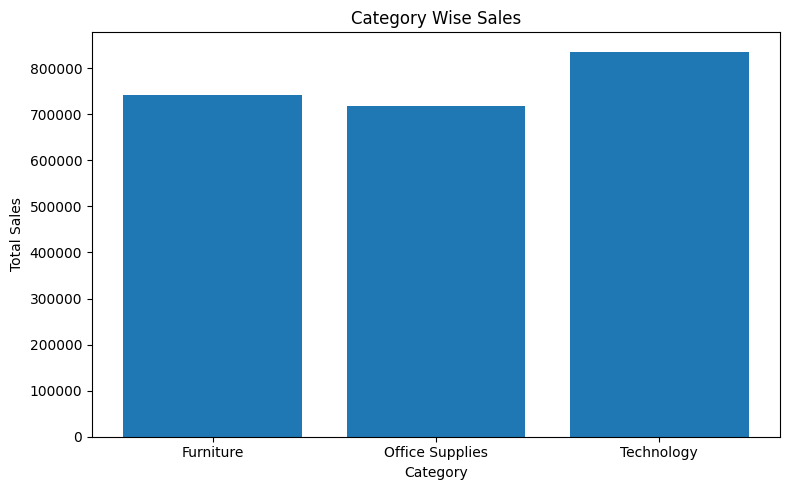

In [10]:
plt.figure(figsize=(8, 5))

plt.bar(category_sales.index, category_sales.values)

plt.title("Category Wise Sales")

plt.xlabel("Category")

plt.ylabel("Total Sales")

plt.tight_layout()

plt.show()

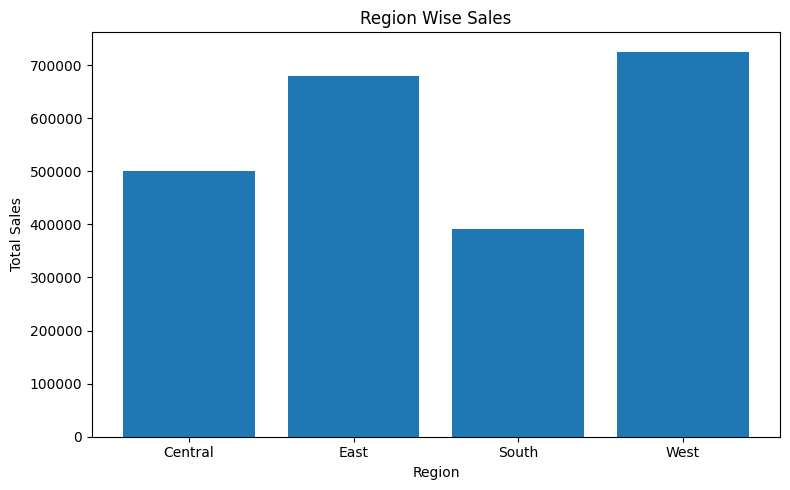

In [11]:
region_sales = df.groupby("Region")["Sales"].sum()

plt.figure(figsize=(8, 5))

plt.bar(region_sales.index, region_sales.values)

plt.title("Region Wise Sales")

plt.xlabel("Region")

plt.ylabel("Total Sales")

plt.tight_layout()

plt.show()

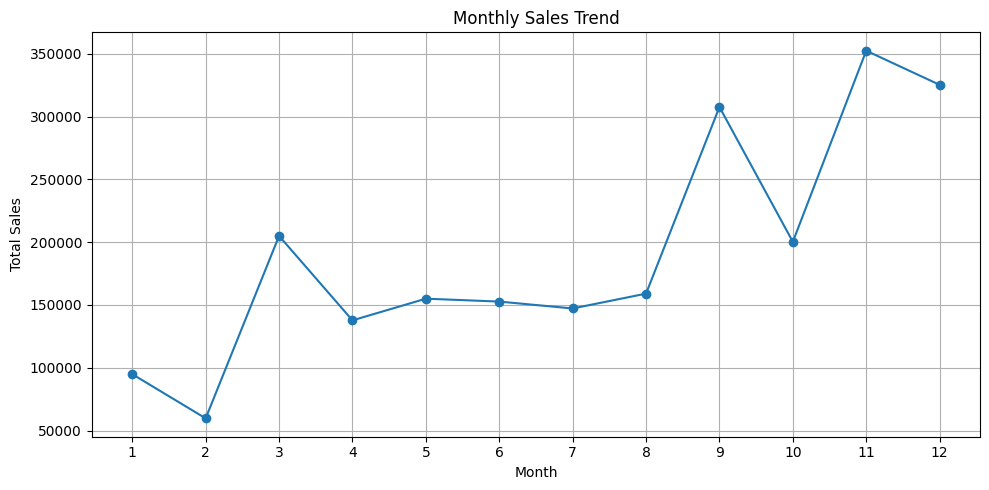

In [13]:
monthly_sales = df.groupby(
    df["Order Date"].dt.month
)["Sales"].sum()

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")

plt.xlabel("Month")

plt.ylabel("Total Sales")

plt.xticks(range(1, 13))

plt.grid(True)

plt.tight_layout()

plt.show()

In [17]:
with pd.ExcelWriter(
    r"C:\Users\hp\Downloads\project3.xlsx",
    engine="openpyxl"
) as writer:
    df.to_excel(writer, sheet_name="Sales_Data", index=False)
    category_sales.to_excel(writer, sheet_name="Category_Sales")
    region_sales.to_excel(writer, sheet_name="Region_Sales")
    monthly_sales.to_excel(writer, sheet_name="Monthly_Sales")

print("Excel File Created Successfully!")

print("Excel File Created Successfully!")

Excel File Created Successfully!
Excel File Created Successfully!
